# Benzamidine unbinding from trypsin: water-mediated routes B and B′

50 PathGennie escape trajectories from the bound state B. Labels: Gaussian mixture on the mean s<sub>t</sub>
(Deep-TICA CV) in the funnel window z = 0.45–1.0 nm (31 B′, 19 B).

* **Ligand-only map**: benzamidine coordinates.
* **Map with water** (paper): benzamidine + the waters occupying the hydration sites V1–V16 in the first frame
  (six waters), matched between trajectories by the Hungarian assignment.

L² distance, σ = median, α = 0. The PLUMED CVs (s<sub>t</sub>, site occupancies) are read from precomputed
COLVAR files.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]          # repository root (notebook lives in systems/<name>/)
sys.path[:0] = [str(ROOT), str(Path.cwd())]
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathfdm import embed
from pathfdm.features import feature_matrix
from pathfdm.surrogate import fit_surrogate
from pathfdm.evaluation import auc_per_coordinate, kmeans_ari, align_signs, compare_embeddings
from pathfdm.plotting import apply_style, plot_space, plot_parity, plot_beeswarm
import load_data as D
apply_style()
N_JOBS = 8

## Load (benzamidine + hydration-site waters)

In [2]:
ts, cvs, labels = D.load("sites", n_jobs=N_JOBS)
lig = ts.solute_only()
print(f"{(labels == 0).sum()} B', {(labels == 1).sum()} B | waters (resids): {ts.water_ids[0]}")

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/topology/PDBParser.py:376: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/topology/PDBParser.py:376: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "


50 trajectories | 18 solute atoms + 6 water oxygens | 403-588 frames | 72 coordinates per frame


31 B', 19 B | waters (resids): [2238, 2121, 7808, 2262, 2799, 9142]


## FDM embeddings

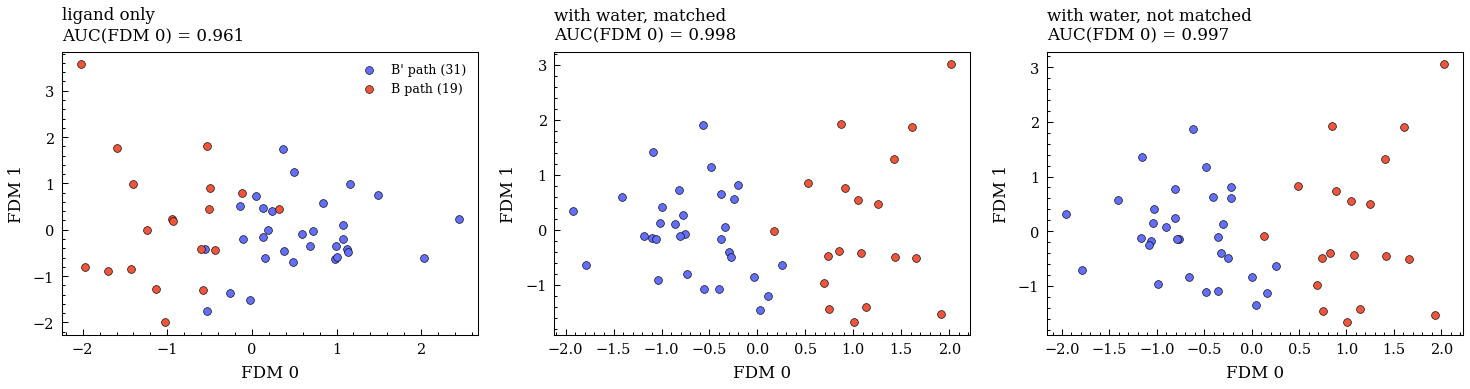

with vs without matching, FDM 0-2: [0.999 0.998 0.998]
All 50 runs start from the same structure, so the six site waters are the same molecules in the same order;
matching therefore changes almost nothing here.


In [3]:
Z_lig = embed(lig.fd, metric="l2", normalize_length=True, n_jobs=N_JOBS)
Z_w = embed(ts.fd, metric="l2", water=True, water_match="dtw", normalize_length=True, n_jobs=N_JOBS)
Z_nm = align_signs(embed(ts.fd, metric="l2", water=False, normalize_length=True, n_jobs=N_JOBS), Z_w)
maps = {"ligand only": Z_lig, "with water, matched": Z_w, "with water, not matched": Z_nm}
fig, axs = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, (name, Z) in zip(axs, maps.items()):
    plot_space(Z, labels, D.LABEL_CONFIG, ax=ax, title=f"{name}\nAUC(FDM 0) = {auc_per_coordinate(Z, labels)[0]:.3f}",
               legend=ax is axs[0])
plt.tight_layout(); plt.show()
print("with vs without matching, FDM 0-2:", np.round(compare_embeddings(Z_nm, Z_w, 3), 3))
print("All 50 runs start from the same structure, so the six site waters are the same molecules in the same order;")
print("matching therefore changes almost nothing here.")

## Surrogate models

The surrogate is an ExtraTrees regressor (500 trees) predicting FDM 0 from the standardized
descriptors. **Out-of-bag R²**: each trajectory predicted by the trees that did not see it. **Cross-validation**:
5-fold, repeated 5 times; R² is the mean ± sd over the 25 folds, and the parity plot shows the mean of the five
held-out predictions of every trajectory. The beeswarm shows the SHAP value of each descriptor for every
trajectory (colour = descriptor value).

Ligand-only map: 9 ligand descriptors (position x, y, r and orientation of benzamidine; z is left out because it
is the progress coordinate), each smoothed on its own. Map with water: radius, cos θ, |n<sub>z</sub>| and the 18
hydration occupancies (V1–V16, F<sub>G</sub>, F<sub>H</sub>).

In [4]:
X_l, n_l = feature_matrix(D.ligand_descriptors(ts), D.LIG_ONLY_TEX, joint=False)
res_l = fit_surrogate(X_l, Z_lig[:, 0], n_l)
X_w, n_w = feature_matrix(D.water_descriptors(ts, cvs), D.water_descriptor_names())
res_w = fit_surrogate(X_w, Z_w[:, 0], n_w)
print("ligand only:    ", res_l.summary())
print("ligand + water: ", res_w.summary())
pd.concat({"ligand only": res_l.table(6), "ligand + water": res_w.table(6)}, axis=1).round(3)

ligand only:     36 descriptors | out-of-bag R2 = 0.329 | 5-fold CV x 5: R2 = 0.193 +/- 0.210
ligand + water:  84 descriptors | out-of-bag R2 = 0.825 | 5-fold CV x 5: R2 = 0.773 +/- 0.139


ligand only                              \
                   feature shap_share frac_folds_rank1   
0            $\sigma(n_y)$      0.108             0.40   
1    $\langle a_y \rangle$      0.083             0.08   
2      $\langle r \rangle$      0.071             0.08   
3  $\langle |n_z| \rangle$      0.062             0.20   
4            $\gamma_1(y)$      0.061             0.04   
5      $\langle x \rangle$      0.050             0.00   

            ligand + water                              
                   feature shap_share frac_folds_rank1  
0  $\langle V_{9} \rangle$      0.296              1.0  
1          $\Delta(V_{9})$      0.143              0.0  
2          $\sigma(V_{9})$      0.121              0.0  
3        $\gamma_1(V_{9})$      0.067              0.0  
4  $\langle V_{8} \rangle$      0.037              0.0  
5    $\langle F_G \rangle$      0.033              0.0

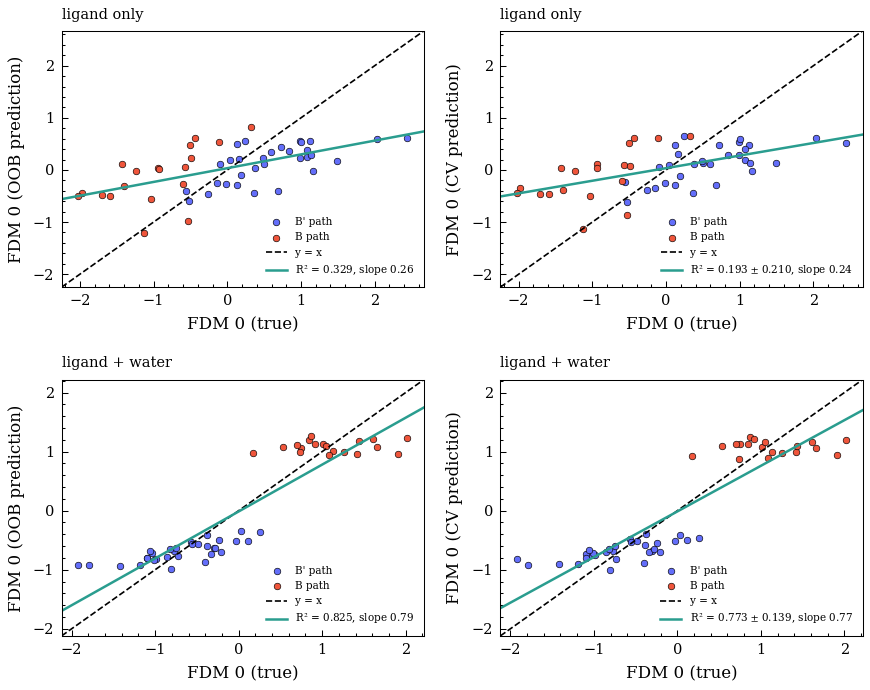

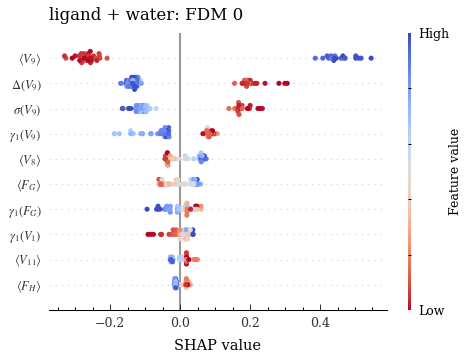

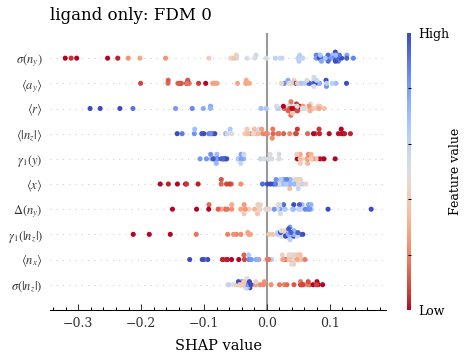

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(6, 4.8))
plot_parity(res_l, labels, D.LABEL_CONFIG, axs=axs[0], title="ligand only")
plot_parity(res_w, labels, D.LABEL_CONFIG, axs=axs[1], title="ligand + water")
plt.tight_layout(); plt.show()
plot_beeswarm(res_w, max_display=10, title="ligand + water: FDM 0"); plt.show()
plot_beeswarm(res_l, max_display=10, title="ligand only: FDM 0"); plt.show()

## Setting: which waters

* `sites` (above): waters in the hydration sites V1–V16 in the first frame
* `near_atom`: waters within 4 Å of Asp189 CG in the first frame
* `closest`: the six waters that come closest to benzamidine at any frame (differ between trajectories)

50 trajectories | 18 solute atoms + 6 water oxygens | 403-588 frames | 72 coordinates per frame


50 trajectories | 18 solute atoms + 2 water oxygens | 403-588 frames | 60 coordinates per frame


50 trajectories | 18 solute atoms + 6 water oxygens | 403-588 frames | 72 coordinates per frame


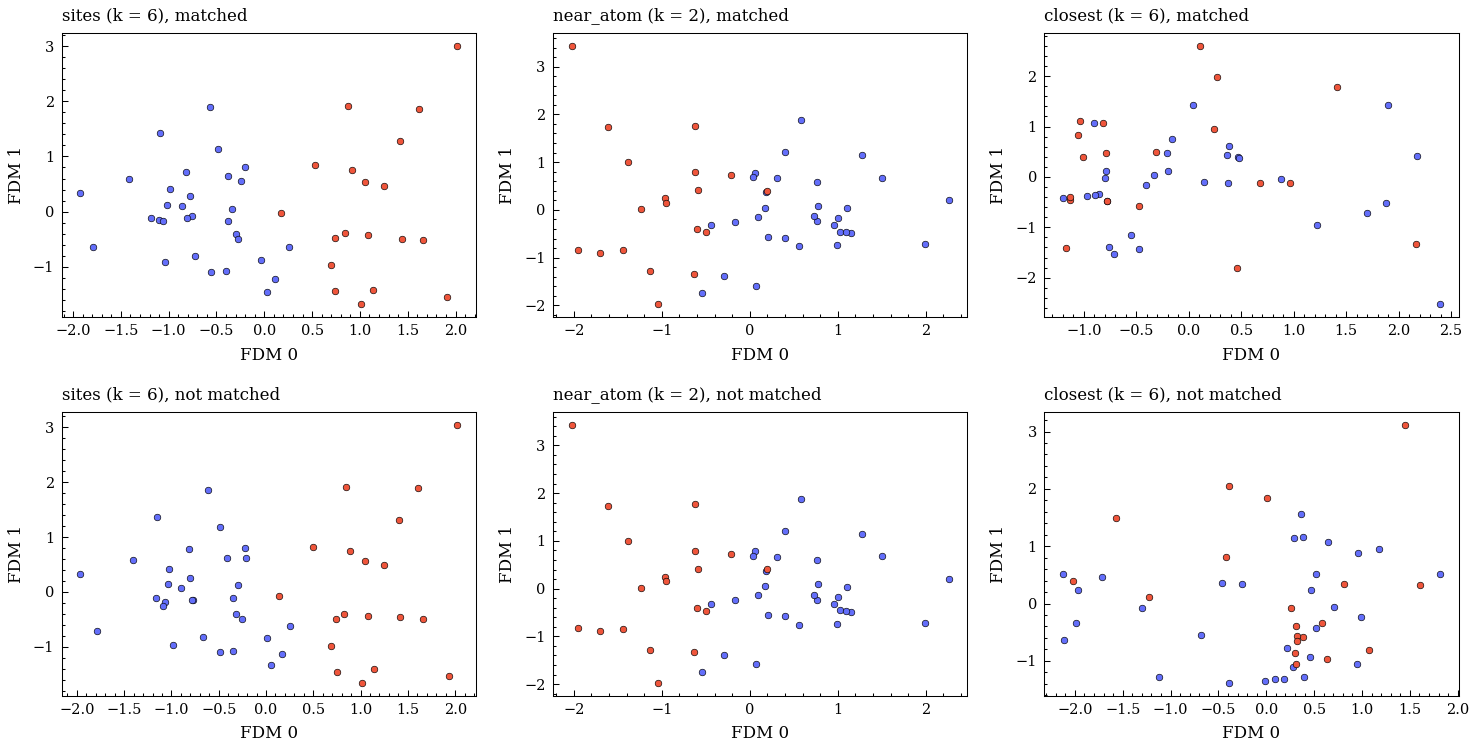

,waters,k,matching,AUC FDM 0,rho FDM 0 vs paper map
0,sites,6,matched,0.998,1.000
1,sites,6,not matched,0.997,0.999
2,near_atom,2,matched,0.976,-0.988
3,near_atom,2,not matched,0.976,-0.988
4,closest,6,matched,0.608,-0.175
5,closest,6,not matched,0.553,0.030


In [ ]:
rows = []
fig, axs = plt.subplots(2, 3, figsize=(10, 5.2))
for col, pick in enumerate(["sites"]):
    tw, _, _ = D.load(pick, k=6, n_jobs=N_JOBS)
    Zm = embed(tw.fd, metric="l2", water=True, water_match="dtw", normalize_length=True, n_jobs=N_JOBS)
    Zn = align_signs(embed(tw.fd, metric="l2", water=False, normalize_length=True, n_jobs=N_JOBS), Zm)
    for row, (kind, Z) in enumerate([("matched", Zm), ("not matched", Zn)]):
        plot_space(Z, labels, D.LABEL_CONFIG, ax=axs[row, col], title=f"{pick} (k = {tw.water_info['k_waters']}), {kind}",
                   legend=False, s=10)
        rows.append({"waters": pick, "k": tw.water_info["k_waters"], "matching": kind,
                     "AUC FDM 0": auc_per_coordinate(Z, labels)[0], "rho FDM 0 vs paper map": compare_embeddings(Z, Z_w, 1)[0]})
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)